# **project-- Gender and Age Prediction**:

**importing** **Libraries**

In [25]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, accuracy_score, classification_report, confusion_matrix

In [29]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

DATASET_DIR = r"/content/UTKFace/UTKFace"

IMAGE_SIZE = 64
CHANNELS = 1
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Download and extract UTKFace, then update DATASET_DIR."
    )

image_paths = []

for ext in ("*.jpg", "*.jpeg", "*.png"):
    image_paths.extend(
        glob.glob(os.path.join(DATASET_DIR, ext))
    )

print("Images found:", len(image_paths))

if not image_paths:
    raise ValueError(
        "No image files found. Check DATASET_DIR and extracted folder structure."
    )

Images found: 23708


In [30]:
data = []

for path in image_paths:
    filename = os.path.basename(path)

    try:
        parts = filename.split("_")

        age = int(parts[0])
        gender = int(parts[1])
        ethnicity = int(parts[2])

        if 0 <= age <= 116 and gender in [0, 1]:
            data.append({
                "image_path": path,
                "age": age,
                "gender": gender,
                "ethnicity": ethnicity
            })

    except (ValueError, IndexError):
        continue

df = pd.DataFrame(data)

print("Total valid images:", len(df))
df.head()

Total valid images: 23705


,image_path,age,gender,ethnicity
0,/content/UTKFace/UTKFace/26_1_4_20170103234115...,26,1,4
1,/content/UTKFace/UTKFace/2_0_2_201612191610468...,2,0,2
2,/content/UTKFace/UTKFace/26_0_1_20170113175136...,26,0,1
3,/content/UTKFace/UTKFace/40_1_0_20170117121910...,40,1,0
4,/content/UTKFace/UTKFace/34_0_1_20170104173008...,34,0,1


In [31]:
print(df.info())

print("\nAge statistics:")
print(df["age"].describe())

print("\nGender distribution:")
print(df["gender"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23705 entries, 0 to 23704
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  23705 non-null  object
 1   age         23705 non-null  int64 
 2   gender      23705 non-null  int64 
 3   ethnicity   23705 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 740.9+ KB
None

Age statistics:
count    23705.000000
mean        33.300907
std         19.885708
min          1.000000
25%         23.000000
50%         29.000000
75%         45.000000
max        116.000000
Name: age, dtype: float64

Gender distribution:
gender
0    12391
1    11314
Name: count, dtype: int64

Missing values:
image_path    0
age           0
gender        0
ethnicity     0
dtype: int64


In [32]:

X = []
y_age = []
y_gender = []

for index, row in df.iterrows():

    img = cv2.imread(row["image_path"])

    if img is None:
        continue

    # Convert BGR to grayscale
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize image
    img = cv2.resize(img, (IMAGE_SIZE, IMAGE_SIZE))

    # Normalize
    img = img / 255.0

    X.append(img)
    y_age.append(row["age"])
    y_gender.append(row["gender"])

# Convert into NumPy arrays
X = np.array(X, dtype=np.float32)
y_age = np.array(y_age, dtype=np.float32)
y_gender = np.array(y_gender, dtype=np.int32)

# Add channel dimension
X = X.reshape(-1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)

print("Image shape:", X.shape)
print("Age shape:", y_age.shape)
print("Gender shape:", y_gender.shape)
print("Pixel minimum:", X.min())
print("Pixel maximum:", X.max())


Image shape: (23705, 64, 64, 1)
Age shape: (23705,)
Gender shape: (23705,)
Pixel minimum: 0.0
Pixel maximum: 1.0


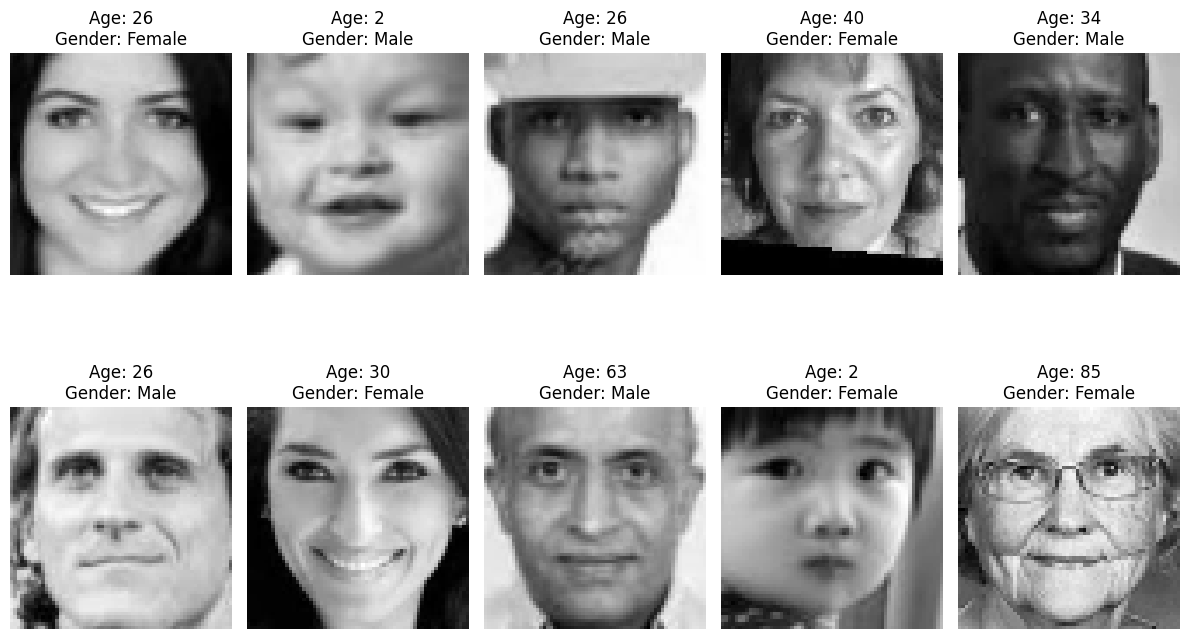

In [33]:

plt.figure(figsize=(12, 8))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X[i].squeeze(), cmap="gray")

    gender = "Male" if y_gender[i] == 0 else "Female"

    plt.title(f"Age: {int(y_age[i])}\nGender: {gender}")
    plt.axis("off")

plt.tight_layout()
plt.show()



In [34]:
from sklearn.model_selection import train_test_split


In [35]:

X_train, X_test, age_train, age_test, gender_train, gender_test = train_test_split(
    X,
    y_age,
    y_gender,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training Images:", X_train.shape)
print("Testing Images:", X_test.shape)

print("Age Training:", age_train.shape)
print("Age Testing:", age_test.shape)

print("Gender Training:", gender_train.shape)
print("Gender Testing:", gender_test.shape)


Training Images: (18964, 64, 64, 1)
Testing Images: (4741, 64, 64, 1)
Age Training: (18964,)
Age Testing: (4741,)
Gender Training: (18964,)
Gender Testing: (4741,)


**Extracting** **image** **features**

In [36]:
print("Training gender distribution:")
print(pd.Series(gender_train).value_counts())

print("\nTesting gender distribution:")
print(pd.Series(gender_test).value_counts())

Training gender distribution:
0    9903
1    9061
Name: count, dtype: int64

Testing gender distribution:
0    2488
1    2253
Name: count, dtype: int64


In [37]:
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    BatchNormalization,
    Flatten,
    Dense,
    Dropout
)
from tensorflow.keras.optimizers import Adam

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [38]:
input_layer = Input(shape=(64, 64, 1))

# CNN Block 1
x = Conv2D(32, (3, 3), activation="relu", padding="same")(input_layer)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)

# CNN Block 2
x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)

# CNN Block 3
x = Conv2D(128, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)

# CNN Block 4
x = Conv2D(256, (3, 3), activation="relu", padding="same")(x)
x = BatchNormalization()(x)
x = MaxPooling2D((2, 2))(x)

# Shared feature extraction
x = Flatten()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)

# Age output - Regression
age_output = Dense(1, activation="linear", name="age_output")(x)

# Gender output - Binary classification
gender_output = Dense(1, activation="sigmoid", name="gender_output")(x)

# Build model
model = Model(
    inputs=input_layer,
    outputs=[age_output, gender_output]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 64, 64,    │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv2d_6[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 8, 8, 128) │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ max_pooling2d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 8, 8, 256) │      1,024 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 4, 4, 256) │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 4096)      │          0 │ max_pooling2d_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 256)       │  1,048,832 │ flatten_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ age_output (Dense)  │ (None, 1)         │        257 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gender_output       │ (None, 1)         │        257 │ dropout_6[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴─────────────────

 Total params: 1,439,106 (5.49 MB)

 Trainable params: 1,438,146 (5.49 MB)

 Non-trainable params: 960 (3.75 KB)

In [39]:
model.compile(
    optimizer=Adam(learning_rate=0.001),

    loss={
        "age_output": "mae",
        "gender_output": "binary_crossentropy"
    },

    loss_weights={
        "age_output": 1.0,
        "gender_output": 1.0
    },

    metrics={
        "age_output": ["mae"],
        "gender_output": ["accuracy"]
    }
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [40]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

In [41]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_age_gender_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.000001,
    verbose=1
)

In [42]:
history = model.fit(
    X_train,
    {
        "age_output": age_train,
        "gender_output": gender_train
    },

    validation_split=0.15,

    epochs=50,
    batch_size=64,

    callbacks=[
        early_stop,
        checkpoint,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/50
252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - age_output_loss: 13.0832 - age_output_mae: 13.0832 - gender_output_accuracy: 0.6489 - gender_output_loss: 1.1712 - loss: 14.2544
Epoch 1: val_loss improved from None to 21.22417, saving model to best_age_gender_model.keras

Epoch 1: finished saving model to best_age_gender_model.keras
252/252 ━━━━━━━━━━━━━━━━━━━━ 45s 113ms/step - age_output_loss: 11.1622 - age_output_mae: 11.1642 - gender_output_accuracy: 0.7022 - gender_output_loss: 0.8135 - loss: 11.9778 - val_age_output_loss: 20.6338 - val_age_output_mae: 20.6033 - val_gender_output_accuracy: 0.6569 - val_gender_output_loss: 0.6216 - val_loss: 21.2242 - learning_rate: 0.0010
Epoch 2/50
252/252 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - age_output_loss: 9.1340 - age_output_mae: 9.1340 - gender_output_accuracy: 0.7720 - gender_output_loss: 0.5066 - loss: 9.6407
Epoch 2: val_loss improved from 21.22417 to 9.45684, saving model to best_age_gender_model.keras

Epoch 2: finished saving model

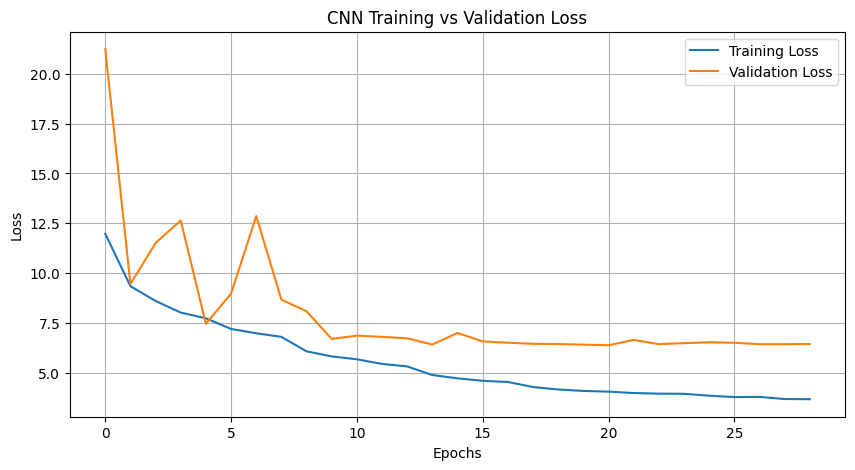

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

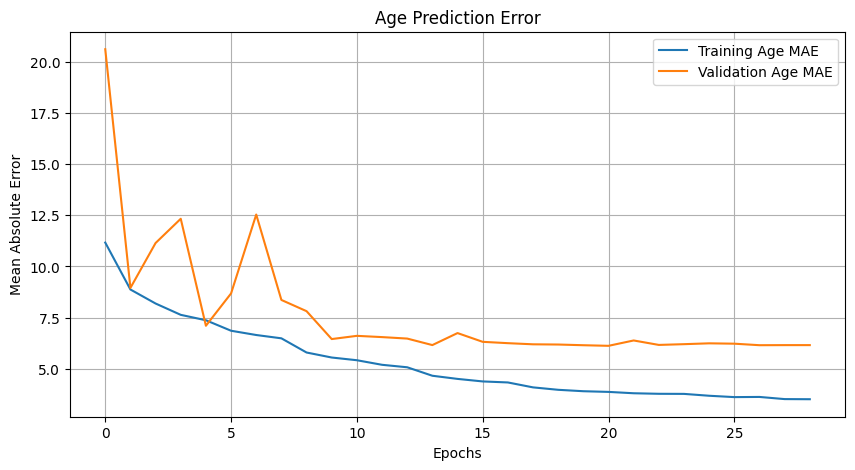

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["age_output_mae"],
    label="Training Age MAE"
)

plt.plot(
    history.history["val_age_output_mae"],
    label="Validation Age MAE"
)

plt.title("Age Prediction Error")
plt.xlabel("Epochs")
plt.ylabel("Mean Absolute Error")
plt.legend()
plt.grid(True)
plt.show()

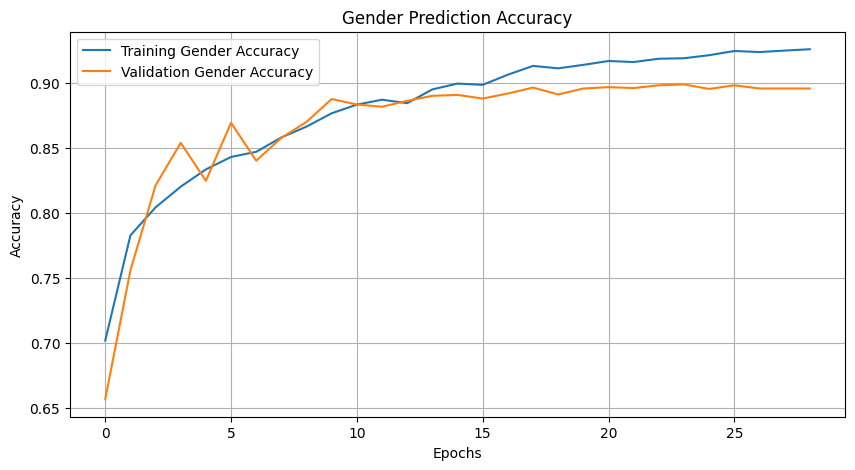

In [45]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["gender_output_accuracy"],
    label="Training Gender Accuracy"
)

plt.plot(
    history.history["val_gender_output_accuracy"],
    label="Validation Gender Accuracy"
)

plt.title("Gender Prediction Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
from tensorflow.keras.models import load_model

model = load_model("best_age_gender_model.keras")

print("Best CNN model loaded successfully!")

Best CNN model loaded successfully!


In [47]:
results = model.evaluate(
    X_test,
    {
        "age_output": age_test,
        "gender_output": gender_test
    },
    batch_size=64,
    verbose=1
)

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

75/75 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - age_output_loss: 5.9790 - age_output_mae: 6.0304 - gender_output_accuracy: 0.8943 - gender_output_loss: 0.2572 - loss: 6.2863
loss: 6.2863
compile_metrics: 5.9790
age_output_loss: 0.2572
gender_output_loss: 6.0304


In [48]:
age_pred, gender_pred = model.predict(X_test)

# Convert predictions
age_pred = age_pred.flatten()

gender_pred = (gender_pred.flatten() >= 0.5).astype(int)

print("Age predictions:", age_pred[:10])
print("Gender predictions:", gender_pred[:10])

149/149 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step
Age predictions: [35.54959   36.632782  55.336025  45.95057   27.878601  30.494282
 32.05316   18.12978    1.0607151 44.951694 ]
Gender predictions: [0 0 0 0 1 1 1 1 0 1]


In [49]:
from sklearn.metrics import mean_absolute_error

age_mae = mean_absolute_error(age_test, age_pred)

print("Age Mean Absolute Error:", round(age_mae, 2), "years")

Age Mean Absolute Error: 6.03 years


In [50]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

gender_accuracy = accuracy_score(
    gender_test,
    gender_pred
)

print("Gender Accuracy:", round(gender_accuracy * 100, 2), "%")

print("\nClassification Report:\n")

print(
    classification_report(
        gender_test,
        gender_pred,
        target_names=["Male", "Female"]
    )
)

Gender Accuracy: 89.43 %

Classification Report:

              precision    recall  f1-score   support

        Male       0.91      0.89      0.90      2488
      Female       0.88      0.90      0.89      2253

    accuracy                           0.89      4741
   macro avg       0.89      0.89      0.89      4741
weighted avg       0.89      0.89      0.89      4741



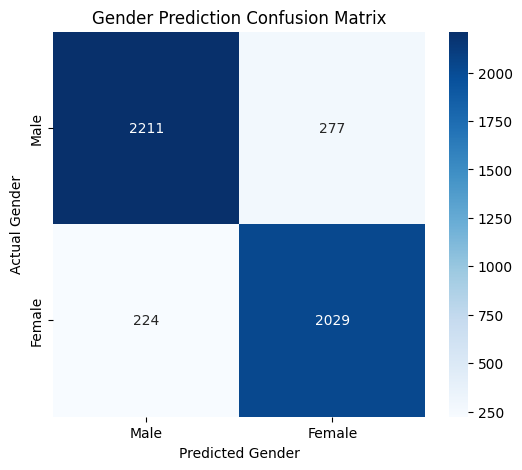

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(gender_test, gender_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Male", "Female"],
    yticklabels=["Male", "Female"]
)

plt.xlabel("Predicted Gender")
plt.ylabel("Actual Gender")
plt.title("Gender Prediction Confusion Matrix")

plt.show()

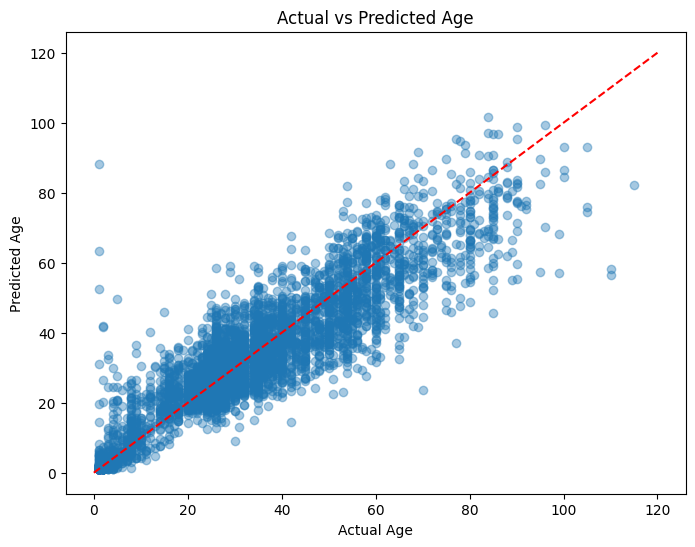

In [52]:
plt.figure(figsize=(8, 6))

plt.scatter(
    age_test,
    age_pred,
    alpha=0.4
)

plt.plot(
    [0, 120],
    [0, 120],
    "r--"
)

plt.xlabel("Actual Age")
plt.ylabel("Predicted Age")
plt.title("Actual vs Predicted Age")

plt.show()

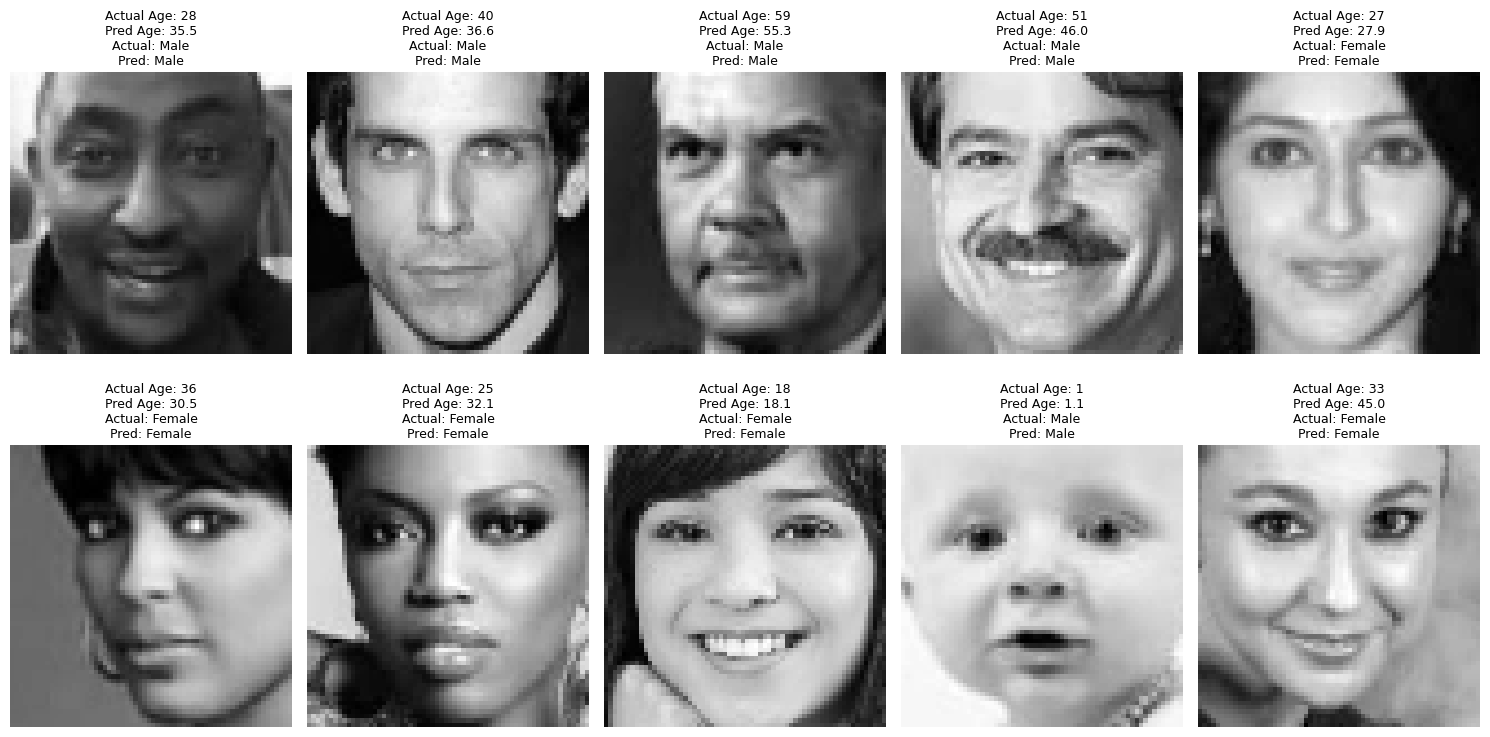

In [53]:
plt.figure(figsize=(15, 8))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual_gender = "Male" if gender_test[i] == 0 else "Female"
    predicted_gender = "Male" if gender_pred[i] == 0 else "Female"

    plt.title(
        f"Actual Age: {int(age_test[i])}\n"
        f"Pred Age: {age_pred[i]:.1f}\n"
        f"Actual: {actual_gender}\n"
        f"Pred: {predicted_gender}",
        fontsize=9
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [54]:
model.save("age_gender_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [55]:
import os

model_path = "age_gender_cnn.keras"

if os.path.exists(model_path):
    print("Model exists:", True)

    size = os.path.getsize(model_path) / (1024 * 1024)

    print("Model size:", round(size, 2), "MB")
else:
    print("Model not found!")

Model exists: True
Model size: 16.55 MB


In [56]:
from tensorflow.keras.models import load_model

loaded_model = load_model("age_gender_cnn.keras")

print("Model loaded successfully!")

print("Input shape:", loaded_model.input_shape)
print("Output shapes:", loaded_model.output_shape)

Model loaded successfully!
Input shape: (None, 64, 64, 1)
Output shapes: [(None, 1), (None, 1)]


In [57]:
age_result, gender_result = loaded_model.predict(
    X_test[:5],
    verbose=0
)

for i in range(5):

    age = float(age_result[i][0])

    gender = "Female" if gender_result[i][0] >= 0.5 else "Male"

    print(
        f"Image {i+1}: "
        f"Predicted Age = {age:.1f}, "
        f"Predicted Gender = {gender}"
    )

Image 1: Predicted Age = 35.5, Predicted Gender = Male
Image 2: Predicted Age = 36.6, Predicted Gender = Male
Image 3: Predicted Age = 55.3, Predicted Gender = Male
Image 4: Predicted Age = 46.0, Predicted Gender = Male
Image 5: Predicted Age = 27.9, Predicted Gender = Female


In [58]:
from google.colab import files

files.download("age_gender_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>